## 1. Introduction

#### Molecular HIV Activity Prediction with Three GCN Variants
**AIMS master's thesis research — Paul Sanyang | Supervisor — Romain Menegaux**

**NOTE:** This notebook includes selected portions of the code developed during my master's thesis.

This notebook implements **(1) node-only GCN**, **(2) additive edge-aware GCN** , and **(3) edge-weighted GCN**.


## 2.  Setup
#### 2.Install dependencies. 

PyTorch Geometric installation depends on the installed PyTorch version; consult the [official installation guide](https://pytorch-geometric.readthedocs.io/en/latest/install/installation.html).

In [1]:
pwd

'/Users/paulsanyang/Desktop/Github_file/masters-thesis-gnn-hiv-prediction'

In [ ]:
%pip install torch-geometric
%pip install ogb rdkit scikit-learn matplotlib seaborn

#### 2.2 Import necessary libraries

In [24]:
import os
import os.path as osp
import pandas as pd
import numpy as np
import torch
import json
from torch import nn
from torch.nn import Linear
import torch.nn.functional as F
import torch.optim as optim
import torch_geometric
from torch_geometric.loader import DataLoader
from torch_geometric.utils import to_dense_adj, to_dense_batch
from ogb.graphproppred import PygGraphPropPredDataset, Evaluator
from ogb.graphproppred.mol_encoder import AtomEncoder, BondEncoder
from rdkit import Chem
from pathlib import Path
from rdkit.Chem import Draw
from rdkit.Chem.Draw import IPythonConsole
import matplotlib.pyplot as plt
import networkx as nx
from tqdm.auto import tqdm
import copy
import random
from sklearn.metrics import (roc_auc_score, average_precision_score, precision_score,
    recall_score, f1_score, matthews_corrcoef, roc_curve, precision_recall_curve,
    confusion_matrix, ConfusionMatrixDisplay)

print('PyTorch:', torch.__version__, '| PyG:', torch_geometric.__version__)

PyTorch: 2.15.0 | PyG: 2.8.1


In [6]:
# Automatically select the best available device
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

print(f"Using device: {device}")


Using device: mps


## 3. Dataset Preparation and Exploratory Analysis

Each graph represents a molecule: atoms are nodes, chemical bonds are edges, and the target is a binary activity label. We use the official OGB **scaffold** split for training, validation, and final testing. The test set is not used to choose architectures or checkpoints.

#### 3.1 Dataset Splitting and Data Loaders

In [9]:
# The official OGB dataset is downloaded/cached in ./data
# Some OGB versions use torch.load without weights_only=False, which PyTorch 2.6+ requires
DATA_ROOT = './data'
_original_load = torch.load
def _trusted_ogb_load(*args, **kwargs):
    kwargs.setdefault('weights_only', False)
    return _original_load(*args, **kwargs)
try:
    torch.load = _trusted_ogb_load
    dataset = PygGraphPropPredDataset(name='ogbg-molhiv', root=DATA_ROOT)
finally:
    torch.load = _original_load
split_idx = dataset.get_idx_split()
batch_size = 64
train_loader = DataLoader(dataset[split_idx['train']], batch_size=batch_size, shuffle=True)
valid_loader = DataLoader(dataset[split_idx['valid']], batch_size=batch_size, shuffle=False)
test_loader = DataLoader(dataset[split_idx['test']], batch_size=batch_size, shuffle=False)
print('Graphs:', len(dataset), '| splits:', {k: len(v) for k,v in split_idx.items()})

Graphs: 41127 | splits: {'train': 32901, 'valid': 4113, 'test': 4113}


In [11]:
labels = dataset.y.view(-1)
inactive = int((labels == 0).sum())
active = int((labels == 1).sum())
print(f'Inactive: {inactive:,} | Active: {active:,} | Total: {len(labels):,}')
print('Example node features:', tuple(dataset[0].x.shape), 'bond features:', tuple(dataset[0].edge_attr.shape))

Inactive: 39,684 | Active: 1,443 | Total: 41,127
Example node features: (19, 9) bond features: (40, 3)


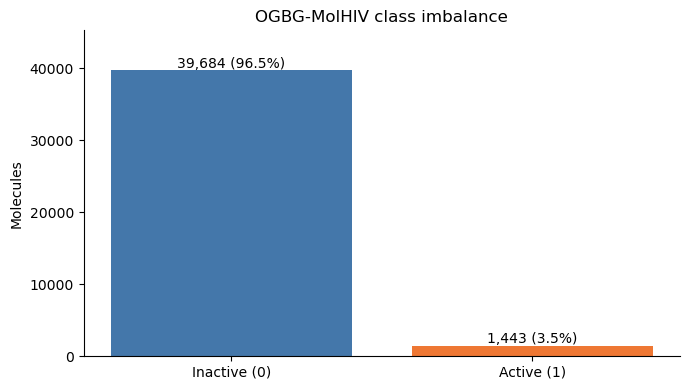

In [13]:
fig, ax = plt.subplots(figsize=(7, 4))
counts = [inactive, active]
bars = ax.bar(['Inactive (0)', 'Active (1)'], counts, color=['#4477AA', '#EE7733'])
for bar, count in zip(bars, counts):
    ax.text(bar.get_x()+bar.get_width()/2, count+350, f'{count:,} ({100*count/len(labels):.1f}%)', ha='center')
ax.set_ylim(0, max(counts)*1.14)
ax.set(title='OGBG-MolHIV class imbalance', ylabel='Molecules')
ax.spines[['top','right']].set_visible(False)
plt.tight_layout(); plt.show()

#### 3.2 Exploratory Analysis of Molecular Bond Features

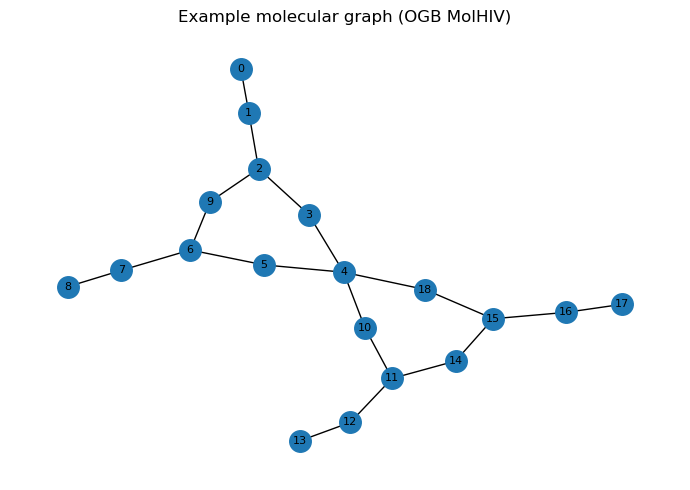

In [16]:
# Illustrative molecular graph: nodes represent atoms and edges represent bonds
graph = dataset[0]
graph_nx = torch_geometric.utils.to_networkx(graph, to_undirected=True)
plt.figure(figsize=(7, 5))
nx.draw_networkx(graph_nx, pos=nx.spring_layout(graph_nx, seed=42), node_size=240,
                 font_size=8, with_labels=True)
plt.title('Example molecular graph (OGB MolHIV)')
plt.axis('off')
plt.tight_layout()
plt.show()

   HIV_active                                             smiles  mol_id
0           0  CCC1=[O+][Cu-3]2([O+]=C(CC)C1)[O+]=C(CC)CC(CC)...     NaN
1           0  C(=Cc1ccccc1)C1=[O+][Cu-3]2([O+]=C(C=Cc3ccccc3...     NaN
2           0                   CC(=O)N1c2ccccc2Sc2c1ccc1ccccc21     NaN
3           0    Nc1ccc(C=Cc2ccc(N)cc2S(=O)(=O)O)c(S(=O)(=O)O)c1     NaN
4           0                             O=S(=O)(O)CCS(=O)(=O)O     NaN


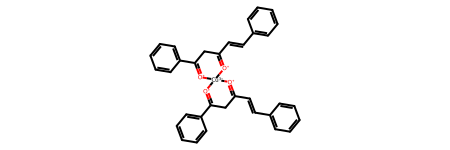

In [18]:
# Locate the SMILES mapping file
smiles_path = Path(dataset.root) / "mapping" / "mol.csv.gz"

# Load molecular SMILES
smiles_df = pd.read_csv(smiles_path)

print(smiles_df.head())

# Select molecule number 1
smiles = smiles_df.iloc[1]["smiles"]

# Convert SMILES into an RDKit molecule
mol = Chem.MolFromSmiles(smiles)

# Display the molecular structure
mol


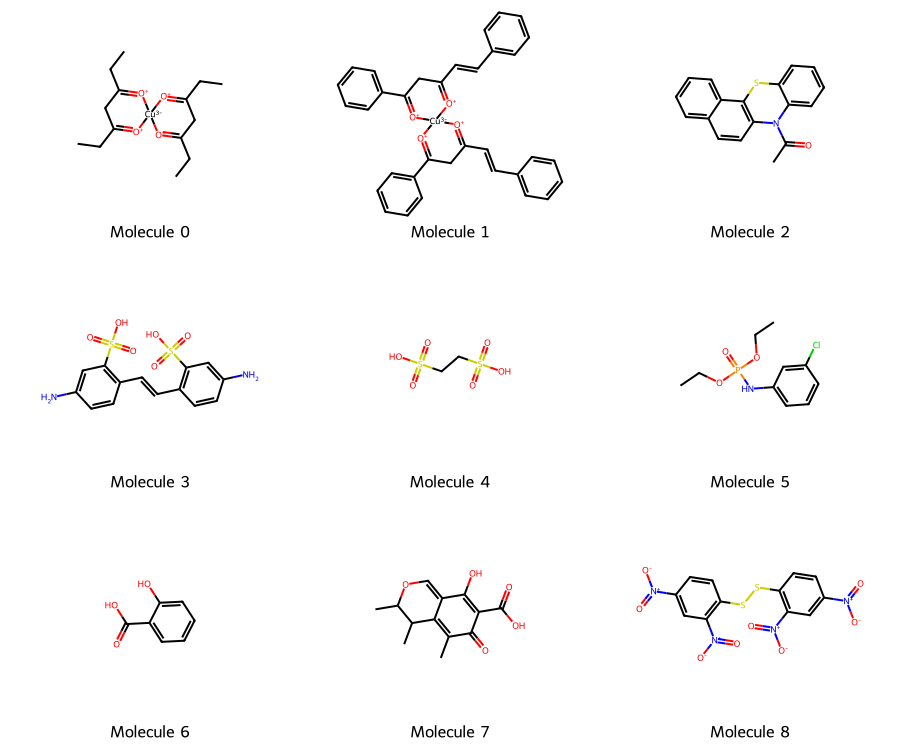

In [20]:
molecules = [
    Chem.MolFromSmiles(s)
    for s in smiles_df["smiles"].iloc[:9]]

img = Draw.MolsToGridImage(
    molecules,
    molsPerRow=3,
    subImgSize=(300, 250),
    legends=[f"Molecule {i}" for i in range(9)])

display(img)

#### 3.3 Molecular Bond Features

In [23]:
batch = next(iter(train_loader))

print("Edge attribute shape:", batch.edge_attr.shape)
print("First 10 bond feature vectors:")
print(batch.edge_attr[:10])

print("\nUnique values for each bond feature:")

for j in range(batch.edge_attr.shape[1]):
    print(
        f"Feature {j}:",
        torch.unique(batch.edge_attr[:, j]).tolist()
    )

Edge attribute shape: torch.Size([3674, 3])
First 10 bond feature vectors:
tensor([[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        [1, 0, 1],
        [1, 0, 1],
        [0, 0, 1],
        [0, 0, 1]])

Unique values for each bond feature:
Feature 0: [0, 1, 2, 3]
Feature 1: [0]
Feature 2: [0, 1]


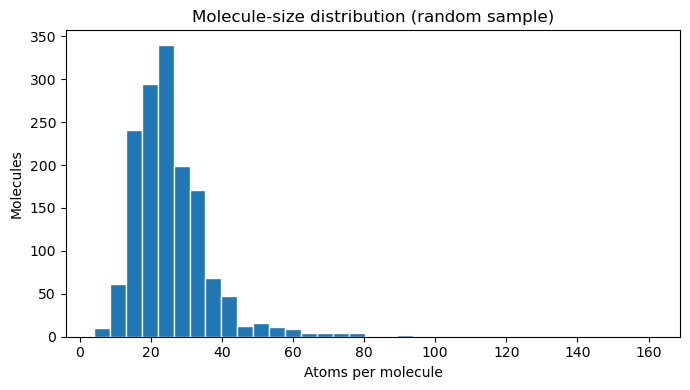

In [25]:
# Distribution of molecule sizes (number of atoms)
rng = np.random.default_rng(5)
subset = rng.choice(len(dataset), size=min(1500, len(dataset)), replace=False)
atom_counts = [dataset[int(i)].num_nodes for i in subset]
plt.figure(figsize=(7, 4))
plt.hist(atom_counts, bins=35, edgecolor='white')
plt.xlabel('Atoms per molecule')
plt.ylabel('Molecules')
plt.title('Molecule-size distribution (random sample)')
plt.tight_layout()
plt.show()

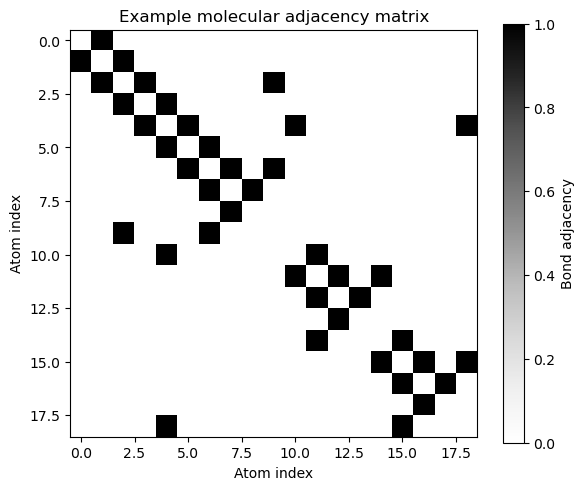

In [27]:
# Example atom adjacency matrix
example = dataset[0]
a = to_dense_adj(example.edge_index, max_num_nodes=example.num_nodes)[0].cpu().numpy()
plt.figure(figsize=(6, 5))
plt.imshow(a, interpolation='nearest', cmap='Greys')
plt.colorbar(label='Bond adjacency')
plt.title('Example molecular adjacency matrix')
plt.xlabel('Atom index')
plt.ylabel('Atom index')
plt.tight_layout()
plt.show()

## 4. Model Architecture
##### Three message-passing approaches


### 4.1 Architectural Overview

We implement and compare three variants of Graph Convolutional Networks (GCNs) for molecular HIV activity prediction:

- **Standard GCN:** Uses atom features and molecular graph connectivity without explicitly incorporating chemical bond features.

- **Additive Edge-Aware GCN:** Incorporates chemical bond embeddings directly into the message-passing mechanism through additive aggregation.

- **Weighted Edge-Aware GCN:** Learns bond-dependent scalar weights that regulate the strength of information propagation between
  neighbouring atoms.

All three architectures share a common framework consisting of an atom encoder, four graph convolutional layers with ReLU activation, global sum pooling, and a linear classification layer. The edge-aware variants additionally employ a bond encoder.

The objective is to investigate whether incorporating chemical bond features improves molecular representation learning and predictive performance, and to assess the relative effectiveness of additive and learnable weighted bond integration strategies compared with the standard GCN baseline.

### 4.2 Mathematical Notation

| Symbol | Description |
| :--- | :--- |
| $G=(V,E)$ | Molecular graph with atoms as nodes and bonds as edges |
| $A$ | Adjacency matrix |
| $I$ | Identity matrix |
| $\widetilde{A}$ | Adjacency matrix with self-loops |
| $\widetilde{D}$ | Degree matrix of $\widetilde{A}$ |
| $\widetilde{d}_i$ | Degree of node $i$ including its self-loop |
| $\widetilde{A}_w^{(l)}$ | Weighted adjacency matrix with self-loops at layer $l$ |
| $\widetilde{D}_w^{(l)}$ | Weighted degree matrix at layer $l$ |
| $H^{(l)}$ | Node representation matrix at layer $l$ |
| $h_i^{(l)}$ | Representation of node $i$ at layer $l$ |
| $W^{(l)}$ | Trainable transformation matrix |
| $b^{(l)}$ | Trainable bias vector |
| $e_{ij}$ | Bond embedding between nodes $i$ and $j$ |
| $w_{ij}^{(l)}$ | Learnable scalar bond weight at layer $l$ |
| $a^{(l)}, c^{(l)}$ | Trainable bond-weighting parameters |
| $\mathcal{N}(i)$ | Set of neighboring nodes of node $i$ |
| $\sigma$ | ReLU activation function |
| $\delta_{ij}$ | Kronecker delta |
| $l$ | Graph convolutional layer index |

### 4.3. Graph Convolution Formulations

#### 4.3.1. Standard GCN (`none`)

$$
\boxed{
H^{(l+1)} = \sigma\left(
\widetilde{D}^{-\frac{1}{2}}
\widetilde{A}
\widetilde{D}^{-\frac{1}{2}}
H^{(l)}W^{(l)} + b^{(l)}
\right)
}
$$

where

$$
\widetilde{A} = A + I, \qquad
\widetilde{D}_{ii} = \sum_j \widetilde{A}_{ij}.
$$

This formulation uses only atom features and graph connectivity,
ignoring explicit bond features.

#### 4.3.2. Additive Edge-Aware GCN (`additive`)

$$
\boxed{
h_i^{(l+1)} = \sigma\left(
W^{(l)}
\left[
\sum_{j \in \mathcal{N}(i) \cup \{i\}}
\frac{h_j^{(l)}}{\sqrt{\widetilde{d}_i \widetilde{d}_j}}
+
\sum_{j \in \mathcal{N}(i)}
\frac{e_{ij}}{\sqrt{\widetilde{d}_i \widetilde{d}_j}}
\right]
+ b^{(l)}
\right)
}
$$

where $e_{ij}$ is the bond embedding between atoms $i$ and $j$.

This formulation directly incorporates bond embeddings into the
aggregated node representations. Bond embeddings are not added
to self-loop messages.

#### 4.3.3. Weighted Edge-Aware GCN (`weighted`)

$$
\boxed{
H^{(l+1)} = \sigma\left(
(\widetilde{D}_w^{(l)})^{-\frac{1}{2}}
\widetilde{A}_w^{(l)}
(\widetilde{D}_w^{(l)})^{-\frac{1}{2}}
H^{(l)}W^{(l)} + b^{(l)}
\right)
}
$$

where the weighted adjacency matrix is defined as

$$
\widetilde{A}_{w,ij}^{(l)}
= A_{ij}w_{ij}^{(l)} + \delta_{ij},
$$

with learnable bond weights

$$
\boxed{
w_{ij}^{(l)} =
2\operatorname{sigmoid}\left(
(a^{(l)})^\top e_{ij} + c^{(l)}
\right)
}
$$

and weighted degree matrix

$$
\widetilde{D}_{w,ii}^{(l)}
= \sum_j \widetilde{A}_{w,ij}^{(l)}.
$$

This formulation uses bond features to learn the strength of
information propagation between neighboring atoms, rather than
directly adding bond embeddings to node representations.

### 4.4 Comparison of Message-Passing Mechanisms

The fundamental difference between the three GCN architectures lies
in how chemical bond features are incorporated into the message-passing
mechanism.

| Feature | Standard GCN | Additive Edge-Aware GCN | Weighted Edge-Aware GCN |
| :--- | :---: | :---: | :---: |
| Atom features | Yes | Yes | Yes |
| Graph connectivity | Yes | Yes | Yes |
| Bond features | No | Yes | Yes |
| Self-loops | Yes | Yes | Yes |
| Symmetric adjacency normalization | Yes | Yes | Yes |
| Direct bond embedding aggregation | No | Yes | No |
| Learnable scalar bond weights | No | No | Yes |
| Bond-dependent adjacency normalization | No | No | Yes |
| Global sum pooling | Yes | Yes | Yes |

Ignoring adjacency normalization and self-loops for simplicity,
the message from node $j$ to node $i$ can be summarized as follows:

| Architecture | Message-Passing Formulation |
| :--- | :--- |
| Standard GCN | $m_{ij}^{(l)} = h_j^{(l)}$ |
| Additive Edge-Aware GCN | $m_{ij}^{(l)} = h_j^{(l)} + e_{ij}$ |
| Weighted Edge-Aware GCN | $m_{ij}^{(l)} = w_{ij}^{(l)}h_j^{(l)}$ |

The standard GCN serves as the baseline model. While the additive
approach enriches node representations by directly incorporating
bond embeddings, the weighted approach uses bond features to
modulate the strength of information propagation between neighboring
nodes.

By maintaining a common architectural framework across the three
models, we aim to assess the impact of different bond-feature
integration strategies on molecular HIV activity prediction.

### 4.5. Model Implementation

In [30]:
class CustomGCNLayer(nn.Module):
    """
    Dense GCN layer with optional additive or weighted bond integration.

    Args:
        hidden_dim (int): Dimension of node and bond embeddings.
        edge_mode (str): Bond integration mode ('none', 'additive',
                         or 'weighted').
    """

    def __init__(self, hidden_dim, edge_mode='weighted'):
        super().__init__()
        if edge_mode not in {'none', 'additive', 'weighted'}:
            raise ValueError('edge_mode must be none, additive, or weighted')
        self.edge_mode = edge_mode
        self.linear = nn.Linear(hidden_dim, hidden_dim)
        self.edge_weight = nn.Linear(hidden_dim, 1) if edge_mode == 'weighted' else None

    def forward(self, x, adj, bond_emb=None):
        # x: [B,N,H]; adj: [B,N,N]; bond_emb: [B,N,N,H]
        if self.edge_mode != 'none' and bond_emb is None:
            raise ValueError('Edge-aware mode requires bond embeddings')

        n = adj.size(-1)
        eye = torch.eye(n, device=adj.device, dtype=adj.dtype).unsqueeze(0)

        if self.edge_mode == 'weighted':
            edge_weights = 2.0 * torch.sigmoid(self.edge_weight(bond_emb).squeeze(-1))
            a_tilde = adj * edge_weights + eye
        else:
            a_tilde = adj + eye

        # Symmetric adjacency normalization
        degree = a_tilde.sum(dim=-1).clamp(min=1)
        inv = degree.pow(-0.5)
        normalized = inv.unsqueeze(-1) * a_tilde * inv.unsqueeze(-2)
        messages = normalized @ x

        if self.edge_mode == 'additive':
            # Bond information is restricted to original edges.
            messages = messages + ((normalized * adj).unsqueeze(-1) * bond_emb).sum(dim=2)

        return self.linear(messages)

class MolecularGCN(nn.Module):
    """
    Graph Convolutional Network for molecular property prediction
    with optional bond feature integration and sum pooling.

    Args:
        hidden_dim (int): Dimension of hidden node representations.
        num_layers (int): Number of graph convolutional layers.
        edge_mode (str): Bond integration mode ('none', 'additive',
                         or 'weighted').
    """

    def __init__(self, hidden_dim=64, num_layers=4, edge_mode='none', dropout=0.0):
        super().__init__()
        self.edge_mode = edge_mode
        self.atom_encoder = AtomEncoder(hidden_dim)
        self.bond_encoder = BondEncoder(hidden_dim) if edge_mode != 'none' else None
        self.convs = nn.ModuleList([
            CustomGCNLayer(hidden_dim, edge_mode) for _ in range(num_layers)])
        self.classifier = nn.Linear(hidden_dim, 1)
        self.dropout = nn.Dropout(dropout)

    def forward(self, data):
        h = self.atom_encoder(data.x.long())
        h, mask = to_dense_batch(h, batch=data.batch)
        n = h.size(1)
        adj = to_dense_adj(data.edge_index, batch=data.batch, max_num_nodes=n)

        bonds = None
        if self.edge_mode != 'none':
            encoded_bonds = self.bond_encoder(data.edge_attr.long())
            bonds = to_dense_adj(data.edge_index, batch=data.batch, edge_attr=encoded_bonds, max_num_nodes=n)

        for conv in self.convs:
            h = self.dropout(F.relu(conv(h, adj, bonds)))
            h = h * mask.unsqueeze(-1)  # Mask padded nodes

        pooled = h.sum(dim=1)  # Graph-level sum pooling
        return self.classifier(pooled)  # Raw logits for BCEWithLogitsLoss

#### 4.6 Minimal shape and gradient checks

These quick tests catch dimension errors and verify that the bond-dependent parameters participate in backpropagation. They do **not** establish full training reproducibility.

In [33]:
sample_batch = next(iter(train_loader))
for mode in ('none', 'additive', 'weighted'):
    probe = MolecularGCN(edge_mode=mode)
    logits = probe(sample_batch)
    assert logits.shape == (sample_batch.num_graphs, 1)
    logits.sum().backward()
    if mode == 'weighted':
        assert probe.convs[0].edge_weight.weight.grad is not None
    if mode != 'none':
        assert any(p.grad is not None for p in probe.bond_encoder.parameters())
    print(mode, '✓', tuple(logits.shape), 'parameters:', sum(p.numel() for p in probe.parameters()))

none ✓ (64, 1) parameters: 27841
additive ✓ (64, 1) parameters: 28673
weighted ✓ (64, 1) parameters: 28933


## 5. Model Training and Evaluation
#### 5.1 Experiment configuration and Hyperparameters

The configuration below controls all architectures. Weighted BCE increases the contribution of positive training examples using $w_+=N_-/N_+$, calculated only from training labels. It is an experimental alternative to ordinary BCE, not a guaranteed ROC-AUC improvement. Validation ROC-AUC selects checkpoints and optionally controls learning rate reduction and early stopping.

Dense bond tensors require $O(BN^2H)$ memory, where $N$ is the largest graph in the batch and $H$ is the hidden dimension. Reduce batch size to 32 if memory is insufficient.

In [35]:
SEED = 5
EPOCHS = 60
BATCH_SIZE = 64
HIDDEN_DIM = 64
NUM_LAYERS = 4
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 0.0
DROPOUT = 0.0
LOSS_MODE = 'weighted'  # 'bce' or 'weighted'
USE_SCHEDULER = True
SCHEDULER_PATIENCE = 10
EARLY_STOPPING = True
PATIENCE = 20
MODES = ('none', 'additive', 'weighted') # Use `MODES = ('none',)` for inexpensive baseline tuning.
RUN_FINAL_TEST = False                   # Keep the test flag disabled until selection is complete.
TRACK_TRAIN_AUC = False
RUN_NAME = 'weighted_b64'

#### 5.2 Training and Evaluation Functions

In [38]:
def seed_everything(seed):
    """Set random seeds to improve reproducibility"""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

train_labels = dataset.y[split_idx['train']].reshape(-1)
num_positive = int((train_labels == 1).sum())
num_negative = int((train_labels == 0).sum())
if not num_positive or not num_negative:
    raise ValueError('Training split must contain both classes.')
if LOSS_MODE not in ('bce', 'weighted'):
    raise ValueError('Unknown LOSS_MODE')
pos_weight = torch.tensor([num_negative / num_positive], dtype=torch.float32, device=device)
criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight if LOSS_MODE == 'weighted' else None)
print(f'Training positives: {num_positive}, negatives: {num_negative}; loss: {LOSS_MODE}')
evaluator = Evaluator(name='ogbg-molhiv')

def train_epoch(model, loader, optimizer):
    """Train the model for one epoch and return the mean loss"""
    model.train()
    total_loss = 0.0
    total_count = 0
    for batch in loader:
        batch = batch.to(device)
        optimizer.zero_grad()
        logits = model(batch)
        targets = batch.y.float().view_as(logits)
        valid = ~torch.isnan(targets)
        if not valid.any():
            continue
        loss = criterion(logits[valid], targets[valid])
        loss.backward()
        optimizer.step()
        count = int(valid.sum().item())
        total_loss += loss.item() * count
        total_count += count
    return total_loss / max(total_count, 1)

@torch.no_grad()
def evaluate_auc(model, loader):
    """Compute ROC-AUC using the official OGB evaluator"""
    model.eval()
    targets, predictions = [], []
    for batch in loader:
        batch = batch.to(device)
        logits = model(batch)
        targets.append(batch.y.cpu())
        predictions.append(torch.sigmoid(logits).cpu())
    result = evaluator.eval({'y_true': torch.cat(targets, dim=0),
                             'y_pred': torch.cat(predictions, dim=0)})
    return float(result['rocauc'])


Training positives: 1232, negatives: 31669; loss: weighted


#### 5.3 Model Training and Checkpoint Selection

All three GCN configurations are trained under the same
hyperparameter settings. The best checkpoint for each model
is selected based on validation ROC-AUC.

In [41]:
results = {}
histories = {}
selected_models = {}

for mode in MODES:
    # Reset random seeds for consistent model comparisons
    seed_everything(SEED)
    model = MolecularGCN(hidden_dim=HIDDEN_DIM, num_layers=NUM_LAYERS, edge_mode=mode, dropout=DROPOUT).to(device)
    optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="max", factor=0.5, patience=SCHEDULER_PATIENCE, min_lr=1e-6) if USE_SCHEDULER else None
    stale = 0
    history = {'epoch': [], 'loss': [], 'valid_auc': [], 'train_auc': [], 'lr': []}
    best_auc = -float('inf')
    best_state = None
    best_epoch = None
    print(f'\nTraining {mode} GCN on {device}')

    for epoch in range(1, EPOCHS + 1):
        loss = train_epoch(model, train_loader, optimizer)
        val_auc = evaluate_auc(model, valid_loader)
        train_auc = evaluate_auc(model, train_loader) if TRACK_TRAIN_AUC else float('nan')
        history['epoch'].append(epoch)
        history['loss'].append(loss)
        history['valid_auc'].append(val_auc)
        history['train_auc'].append(train_auc)

        history['lr'].append(optimizer.param_groups[0]['lr'])
        # Select the best checkpoint based on validation ROC-AUC
        if np.isfinite(val_auc) and val_auc > best_auc:
            best_auc = val_auc
            best_epoch = epoch
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            stale = 0
        else:
            stale += 1
        if scheduler is not None:
            scheduler.step(val_auc)
        if epoch == 1 or epoch % 5 == 0 or epoch == EPOCHS:
            print(f'Epoch {epoch:3d} | loss={loss:.4f} | valid ROC-AUC={val_auc:.4f}')

        if EARLY_STOPPING and stale >= PATIENCE:
            print(f'Early stopping at epoch {epoch}')
            break

    if best_state is None:
        raise RuntimeError(f'No valid validation ROC-AUC for {mode}')

    # Restore the best checkpoint for final evaluation
    model.load_state_dict(best_state)
    histories[mode] = history
    selected_models[mode] = model
    results[mode] = {'best_epoch': best_epoch, 'validation_rocauc': best_auc}
    print(f'Best checkpoint: epoch {best_epoch}; validation ROC-AUC={best_auc:.4f}')

print('\nNew validation results (NOT thesis historical results):')
print(pd.DataFrame(results).T.to_string())


Training none GCN on mps
Epoch   1 | loss=1.3077 | valid ROC-AUC=0.6522
Epoch   5 | loss=1.1205 | valid ROC-AUC=0.7651
Epoch  10 | loss=1.0667 | valid ROC-AUC=0.7666
Epoch  15 | loss=1.0142 | valid ROC-AUC=0.7734
Epoch  20 | loss=0.9676 | valid ROC-AUC=0.7770
Epoch  25 | loss=0.9418 | valid ROC-AUC=0.7756
Epoch  30 | loss=0.8690 | valid ROC-AUC=0.7680
Epoch  35 | loss=0.8351 | valid ROC-AUC=0.7750
Epoch  40 | loss=0.8194 | valid ROC-AUC=0.7927
Epoch  45 | loss=0.7979 | valid ROC-AUC=0.7929
Epoch  50 | loss=0.7834 | valid ROC-AUC=0.7937
Epoch  55 | loss=0.7226 | valid ROC-AUC=0.7925
Early stopping at epoch 59
Best checkpoint: epoch 39; validation ROC-AUC=0.7990

Training additive GCN on mps
Epoch   1 | loss=1.2920 | valid ROC-AUC=0.6705
Epoch   5 | loss=1.1376 | valid ROC-AUC=0.7205
Epoch  10 | loss=1.0529 | valid ROC-AUC=0.6712
Epoch  15 | loss=1.0157 | valid ROC-AUC=0.7472
Epoch  20 | loss=0.9829 | valid ROC-AUC=0.7539
Epoch  25 | loss=0.9497 | valid ROC-AUC=0.7895
Epoch  30 | loss=0

#### 5.4 Save Models

In [44]:
checkpoint_dir = Path('checkpoints') / RUN_NAME
checkpoint_dir.mkdir(parents=True, exist_ok=True)
for mode, model in selected_models.items():
    torch.save({k: v.detach().cpu() for k, v in model.state_dict().items()}, checkpoint_dir / f'gcn_{mode}.pt')
config = {k: globals()[k] for k in ('SEED', 'EPOCHS', 'BATCH_SIZE', 'HIDDEN_DIM', 'NUM_LAYERS', 'LEARNING_RATE', 'WEIGHT_DECAY', 'DROPOUT', 'LOSS_MODE', 'USE_SCHEDULER', 'SCHEDULER_PATIENCE', 'EARLY_STOPPING', 'PATIENCE', 'MODES')}
(checkpoint_dir / 'config.json').write_text(json.dumps(config, indent=2))
pd.DataFrame(results).T.to_csv(checkpoint_dir / 'validation_results.csv')
for mode, history in histories.items():
    pd.DataFrame(history).to_csv(checkpoint_dir / f'{mode}_history.csv', index=False)

## 6. Experimental Results and Model Comparison
#### 6.1 Validation ROC-AUC and Parameter Comparison

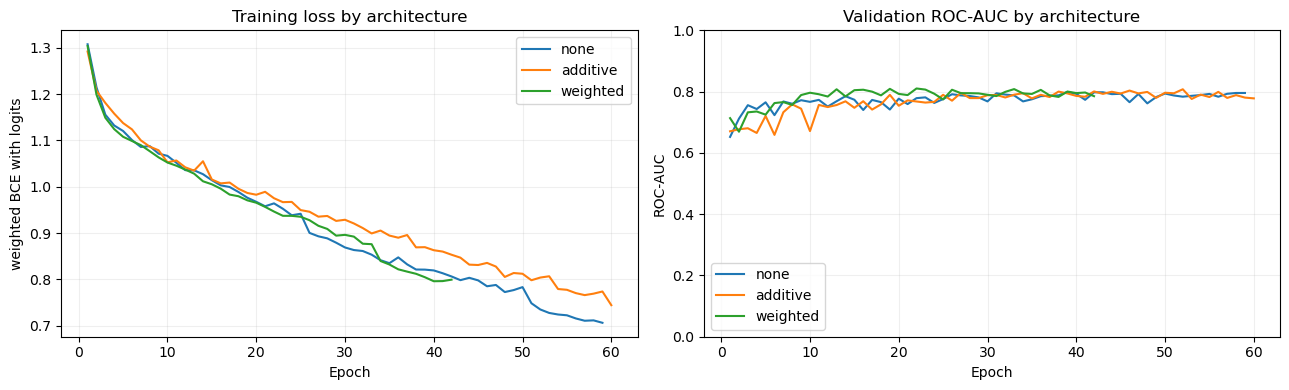

In [47]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for mode, history in histories.items():
    axes[0].plot(history['epoch'], history['loss'], label=mode)
    axes[1].plot(history['epoch'], history['valid_auc'], label=mode)
axes[0].set(title='Training loss by architecture', xlabel='Epoch', ylabel=f'{LOSS_MODE} BCE with logits')
axes[1].set(title='Validation ROC-AUC by architecture', xlabel='Epoch', ylabel='ROC-AUC', ylim=(0, 1))
for ax in axes:
    ax.legend()
    ax.grid(alpha=0.2)
plt.tight_layout(); plt.show()

## 6.2 Training Dynamics and Validation Performance

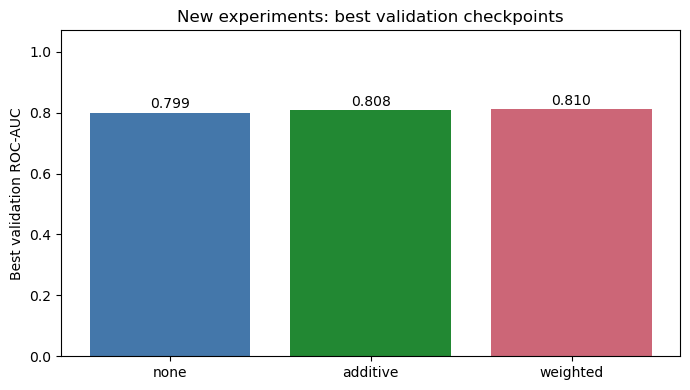

In [50]:
names = list(results)
values = [results[m]['validation_rocauc'] for m in names]
fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(names, values, color=['#4477AA', '#228833', '#CC6677'])
for bar, value in zip(bars, values):
    ax.text(bar.get_x()+bar.get_width()/2, value+0.015, f'{value:.3f}', ha='center')
ax.set(ylim=(0, 1.07), ylabel='Best validation ROC-AUC', title='New experiments: best validation checkpoints')
plt.tight_layout(); plt.show()

#### Models

#### 6.3 Held-out Test Evaluation

ROC-AUC (already used for checkpoint selection) and average precision (AP) measure ranking performance without a classification threshold. AP is particularly useful for the imbalanced MolHIV dataset. Precision, recall, F1 and Matthews correlation coefficient (MCC) are computed at a threshold selected separately for each model by maximizing F1 on the validation split. Ties use the highest threshold.

Set `RUN_FINAL_TEST=True` only after model selection is finalized. Each selected model requires only one validation and one test inference pass for this analysis. Results are single-seed estimates, not evidence of statistical significance.

In [83]:
RUN_FINAL_TEST=True

In [85]:
@torch.no_grad()
def collect_predictions(model, loader):
    """Return aligned binary labels and probabilities, excluding missing labels"""
    model.eval()
    labels, scores = [], []
    for batch in loader:
        batch = batch.to(device)
        logits = model(batch).reshape(-1)
        y = batch.y.reshape(-1)
        mask = ~torch.isnan(y.float())
        labels.append(y[mask].cpu().numpy())
        scores.append(torch.sigmoid(logits[mask]).cpu().numpy())
    y = np.concatenate(labels).astype(int)
    p = np.concatenate(scores)
    if set(np.unique(y)) != {0, 1} or not np.isfinite(p).all():
        raise ValueError('Evaluation requires both binary classes and finite scores.')
    return y, p

def select_f1_threshold(y, p):
    """Select the threshold that maximizes the validation F1-score"""
    precision, recall, thresholds = precision_recall_curve(y, p)

    # The final precision/recall pair has no corresponding threshold
    numerator = 2 * precision[:-1] * recall[:-1]
    denominator = precision[:-1] + recall[:-1]
    f1 = np.divide(numerator, denominator, out=np.zeros_like(numerator),
                   where=denominator > 0)

    return float(thresholds[np.flatnonzero(f1 == f1.max())[-1]])

def binary_metrics(y, p, threshold):
    """Compute binary classification metrics at a given threshold"""
    predicted = (p >= threshold).astype(int)
    return {
        'test_rocauc': roc_auc_score(y, p),
        'test_average_precision': average_precision_score(y, p),
        'test_precision': precision_score(y, predicted, zero_division=0),
        'test_recall': recall_score(y, predicted, zero_division=0),
        'test_f1': f1_score(y, predicted, zero_division=0),
        'test_mcc': matthews_corrcoef(y, predicted),
        'validation_threshold': threshold,}

test_predictions = {}
if RUN_FINAL_TEST:
    for mode, model in selected_models.items():
        y_valid, p_valid = collect_predictions(model, valid_loader)
        threshold = select_f1_threshold(y_valid, p_valid)
        y_test, p_test = collect_predictions(model, test_loader)
        metrics = binary_metrics(y_test, p_test, threshold)
        # Verify consistency with the official OGB ROC-AUC evaluator.
        official_auc = evaluator.eval({'y_true': y_test.reshape(-1, 1),
                                       'y_pred': p_test.reshape(-1, 1)})['rocauc']
        assert np.isclose(metrics['test_rocauc'], official_auc)
        results[mode].update(metrics)
        test_predictions[mode] = (y_test, p_test, threshold)
    evaluation_table = pd.DataFrame(results).T
    print('FINAL held-out test results (new experiments):')
    print(evaluation_table.to_string(float_format=lambda x: f'{x:.4f}'))
else:
    print('Held-out test evaluation skipped (RUN_FINAL_TEST=False).')

FINAL held-out test results (new experiments):
          best_epoch  validation_rocauc  test_rocauc  test_average_precision  test_precision  test_recall  test_f1  test_mcc  validation_threshold
none         39.0000             0.7990       0.7654                  0.2380          0.4026       0.2385   0.2995    0.2929                0.9459
additive     52.0000             0.8076       0.7072                  0.1328          0.2308       0.1385   0.1731    0.1583                0.9096
weighted     22.0000             0.8102       0.7484                  0.2227          0.4286       0.2077   0.2798    0.2830                0.9352


#### 6.4 ROC and Precision–Recall Curves

The dashed ROC reference represents random ranking. The horizontal precision–recall reference is the positive-class prevalence. AP is the step-weighted average precision.

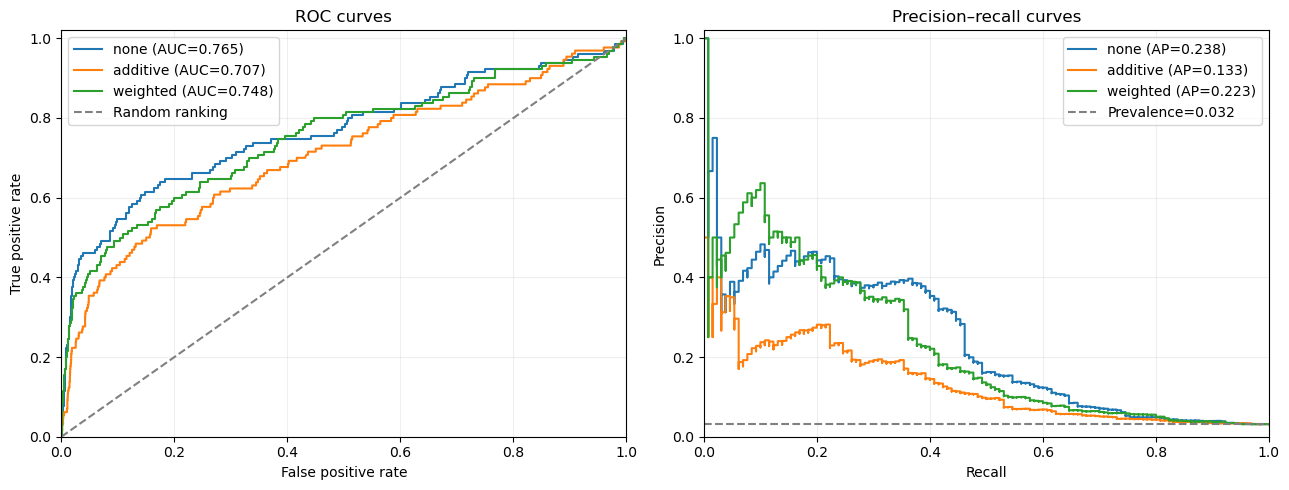

In [87]:
if test_predictions:
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    for mode, (y, p, threshold) in test_predictions.items():
        fpr, tpr, _ = roc_curve(y, p)
        precision, recall, _ = precision_recall_curve(y, p)
        axes[0].plot(fpr, tpr, label=f"{mode} (AUC={roc_auc_score(y, p):.3f})")
        axes[1].step(recall, precision, where='post',
                     label=f"{mode} (AP={average_precision_score(y, p):.3f})")
    axes[0].plot([0, 1], [0, 1], '--', color='gray', label='Random ranking')
    prevalence = next(iter(test_predictions.values()))[0].mean()
    axes[1].axhline(prevalence, linestyle='--', color='gray',
                    label=f'Prevalence={prevalence:.3f}')
    axes[0].set(xlabel='False positive rate', ylabel='True positive rate', title='ROC curves')
    axes[1].set(xlabel='Recall', ylabel='Precision', title='Precision–recall curves')
    for ax in axes:
        ax.set(xlim=(0, 1), ylim=(0, 1.02))
        ax.legend(loc='best')
        ax.grid(alpha=0.2)
    fig.tight_layout()
    plt.show()
else:
    print('Run Section 6.3 with RUN_FINAL_TEST=True first.')

#### 6.5 Confusion Matrices

Rows are true labels and columns are predicted labels. Each matrix uses the corresponding validation-selected threshold and reports raw molecule counts.

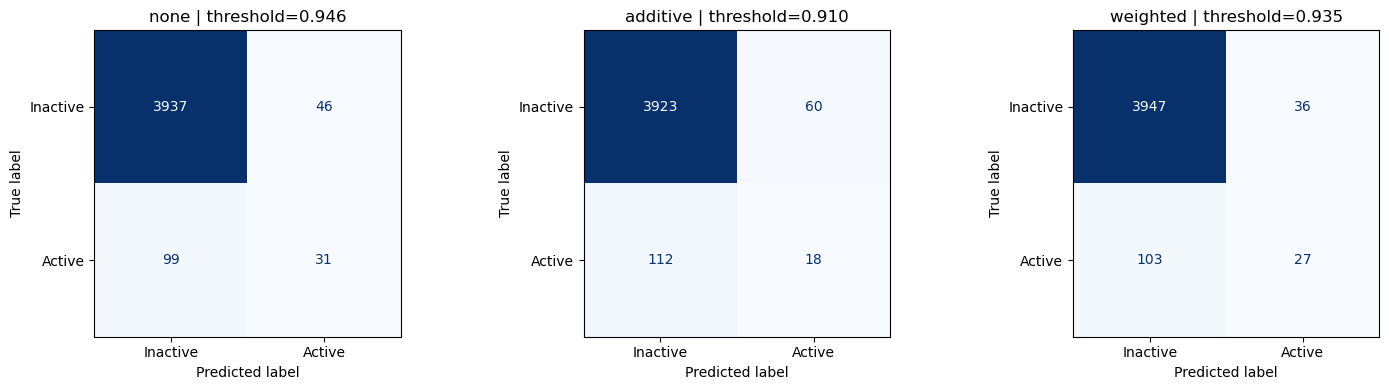

In [93]:
if test_predictions:
    fig, axes = plt.subplots(1, len(test_predictions),
                             figsize=(5 * len(test_predictions), 4), squeeze=False)
    for ax, (mode, (y, p, threshold)) in zip(axes.ravel(), test_predictions.items()):
        cm = confusion_matrix(y, (p >= threshold).astype(int), labels=[0, 1])
        ConfusionMatrixDisplay(cm, display_labels=['Inactive', 'Active']).plot(
            ax=ax, cmap='Blues', colorbar=False, values_format='d')
        ax.set_title(f'{mode} | threshold={threshold:.3f}')
    fig.tight_layout()
    plt.show()
else:
    print('Run Section 6.3 with RUN_FINAL_TEST=True first.')

## 7. Diagnostic Analysis of Edge-Aware Learning
#### 7.1 Symmetry of Learned Edge Weights
This checks whether your trained model assigns equal weights to both directions of the same chemical bond.

In [96]:
if 'weighted' not in selected_models:
    print('Weighted model not trained; diagnostic skipped.')
else:
    model = selected_models['weighted']
    model.eval()

    batch = next(iter(train_loader)).to(device)

    with torch.no_grad():
        encoded_bonds = model.bond_encoder(batch.edge_attr.long())

        h = model.atom_encoder(batch.x.long())
        h, mask = to_dense_batch(h, batch=batch.batch)
        n = h.size(1)

        adj = to_dense_adj(batch.edge_index, batch=batch.batch, max_num_nodes=n)

        bonds = to_dense_adj(batch.edge_index, batch=batch.batch, edge_attr=encoded_bonds, max_num_nodes=n)

        for i, conv in enumerate(model.convs):
            edge_weights = 2.0 * torch.sigmoid(conv.edge_weight(bonds).squeeze(-1))

            weighted_adj = adj * edge_weights

            asymmetry = (
                weighted_adj -
                weighted_adj.transpose(1, 2)).abs().max()

            print(
                f"Layer {i+1} maximum asymmetry: "
                f"{asymmetry.item():.10f}")

Layer 1 maximum asymmetry: 0.0000000000
Layer 2 maximum asymmetry: 0.0000000000
Layer 3 maximum asymmetry: 0.0000000000
Layer 4 maximum asymmetry: 0.0000000000


#### 7.2 Distribution of Learned Weights by Chemical Bond Type
Let's investigate how the model assigns different weights to different chemical bond types across the graph convolutional layers.

In [99]:
if 'weighted' not in selected_models:
    print('Weighted model not trained; diagnostic skipped.')
else:
    #
    model = selected_models['weighted']
    model.eval()

    batch = next(iter(train_loader)).to(device)

    bond_names = {
        0: "Single",
        1: "Double",
        2: "Triple",
        3: "Aromatic"}

    with torch.no_grad():
        bond_emb = model.bond_encoder(
            batch.edge_attr.long())

        bond_types = batch.edge_attr[:, 0]

        for layer_idx, conv in enumerate(model.convs):
            weights = 2.0 * torch.sigmoid(
                conv.edge_weight(bond_emb).squeeze(-1))

            print(f"\nLayer {layer_idx + 1}")

            for bond_type in torch.unique(bond_types).tolist():
                selected = weights[bond_types == bond_type]

                print(f"{bond_names.get(bond_type, str(bond_type))}: "
                    f"count={selected.numel()}, "
                    f"mean={selected.mean().item():.6f}, "
                    f"std={selected.std(unbiased=False).item():.6f}")


Layer 1
Single: count=1642, mean=0.666329, std=0.128188
Double: count=286, mean=1.326142, std=0.113451
Triple: count=12, mean=0.726255, std=0.143756
Aromatic: count=1442, mean=1.172367, std=0.000000

Layer 2
Single: count=1642, mean=1.915630, std=0.046555
Double: count=286, mean=0.283035, std=0.126820
Triple: count=12, mean=1.776446, std=0.102793
Aromatic: count=1442, mean=1.768388, std=0.000000

Layer 3
Single: count=1642, mean=1.428000, std=0.867088
Double: count=286, mean=0.944672, std=0.497415
Triple: count=12, mean=1.402499, std=0.597377
Aromatic: count=1442, mean=0.000239, std=0.000000

Layer 4
Single: count=1642, mean=0.007954, std=0.004512
Double: count=286, mean=1.046925, std=0.390565
Triple: count=12, mean=0.362294, std=0.312283
Aromatic: count=1442, mean=0.000314, std=0.000000


#### 7.3 Analysis of Edge-Weight Parameter Updates
Let's examine whether the parameters of your trained weighted GCN changed from their zero-initialised values. This section assumes that you trained the model using zero initialisation.

In [102]:
if 'weighted' not in selected_models:
    print('Weighted model not trained; diagnostic skipped.')
else:
    model = selected_models['weighted']
    model.eval()

    print("Edge-Weight Parameter Analysis")

    for i, conv in enumerate(model.convs):
        W = conv.edge_weight.weight.detach()
        b = conv.edge_weight.bias.detach()

        print(f"\nLayer {i + 1}")

        print(
            f"Weight maximum absolute value: "
            f"{W.abs().max().item():.10f}")

        print(
            f"Weight mean absolute value: "
            f"{W.abs().mean().item():.10f}")

        print(
            f"Bias absolute value: "
            f"{b.abs().max().item():.10f}")

Edge-Weight Parameter Analysis

Layer 1
Weight maximum absolute value: 0.1744956672
Weight mean absolute value: 0.0453377031
Bias absolute value: 0.0867222100

Layer 2
Weight maximum absolute value: 0.5077517629
Weight mean absolute value: 0.1556364596
Bias absolute value: 0.1823267490

Layer 3
Weight maximum absolute value: 0.9008166790
Weight mean absolute value: 0.3500747085
Bias absolute value: 0.0859848931

Layer 4
Weight maximum absolute value: 0.6154015660
Weight mean absolute value: 0.2913155854
Bias absolute value: 0.3629545867


### 7.4 Check edge-weight gradients

In [105]:
if 'weighted' not in selected_models:
    print('Weighted model not trained; diagnostic skipped.')
else:
    # Gradient Analysis of Edge-Weight Parameters

    model = selected_models['weighted']
    model.eval()

    batch = next(iter(train_loader)).to(device)

    model.zero_grad(set_to_none=True)

    logits = model(batch).view(-1)
    targets = batch.y.float().view(-1)

    valid = torch.isfinite(targets)

    loss = criterion(
        logits[valid],
        targets[valid])

    loss.backward()

    for i, conv in enumerate(model.convs):
        grad_W = conv.edge_weight.weight.grad
        grad_b = conv.edge_weight.bias.grad

        print(f"\nLayer {i + 1}")

        print(
            "Weight gradient max:",
            None if grad_W is None
            else f"{grad_W.abs().max().item():.10f}")

        print(
            "Bias gradient max:",
            None if grad_b is None
            else f"{grad_b.abs().max().item():.10f}")

    model.zero_grad(set_to_none=True)
    model.eval()


Layer 1
Weight gradient max: 0.0333407000
Bias gradient max: 0.0278470553

Layer 2
Weight gradient max: 0.0031789513
Bias gradient max: 0.0004405375

Layer 3
Weight gradient max: 0.0004362357
Bias gradient max: 0.0005536085

Layer 4
Weight gradient max: 0.0008365178
Bias gradient max: 0.0012502270


In [107]:
print('PyTorch:', torch.__version__)
print('PyG:', torch_geometric.__version__)
print('Device:', device)
print('Seed:', SEED, '| epochs:', EPOCHS, '| batch size:', batch_size)
print('Model modes:', MODES)

PyTorch: 2.15.0
PyG: 2.8.1
Device: mps
Seed: 5 | epochs: 60 | batch size: 64
Model modes: ('none', 'additive', 'weighted')
